# Milestone Project Phase 1


## Introduction
Nama: Rachmadini Noveliq Permana Putri

Batch: 043

Project data analytics ini bertujuan untuk membantu client bisnis gym mengetahui apa saja yang mempengaruhi churn membership yang tinggi dan next step apa saja yang bisa dilakukan untuk mengatasi hal tersebut.

## Problem Statement and Dataset Description

**Topik permasalahan:**
Dalam bisnis fitness & wellness, terdapat trend 'new year new me' setiap awal tahun baru di mana banyak sekali member baru yang bersemangat mendaftar di Januari untuk mencapai body goals sebagai resolusi tahun barunya. 

Namun sebagaimana layaknya sebuah trend, ketika sudah berakhir masanya maka akan berakhir pula ombaknya. Ketika bulan Februari datang akan banyak sekali member baru yang berhenti berlangganan. 

**Latar Belakang:**
Sama halnya seperti yang terjadi pada client kali ini. Meski trend ini merupakan hal yang pasti terjadi setiap tahun dan sebagai imbasnya akan terjadi churn yang sangat tinggi di Bulan Februari, apakah ada upaya yang bisa dilakukan client dalam memperkecil angka churn ketika high season selanjutnya datang?

### Problem Statement
Untuk memperjelas arah dan tujuan spesifik yang ingin dicapai oleh client, kita bisa break down ke dalam framework berikut:

Specific = Menekan jumlah member yang membatalkan membershipnya dan meningkatkan kesetiaan pelanggan

Measurable = Menurunkan angka membership churn sebanyak 50%

Achievable = Dengan cara menganalisa apa faktor yang membuat member aktif tetap rajin datang dan termotivasi kemudian melakukan peningkatan pada fasilitas dan kelas yang dimiliki agar lebih menarik bagi member yang kurang termotivasi 

Relevant = Meningkatkan kesetiaan pelanggan dan menurunkan membership churn melalui peningkatan produk dan layanan bisa membuat gym ini tidak kalah saing dengan gym lain sehingga akhirnya akan bisa membantu meningkatkan revenue 

Time-Bound = Target diharapkan bisa tercapai sebelum 'summer body prep' high season selanjutnya datang sekitar bulan April dan Mei tahun ini.  

**Problem statement:**
Agar bisa bersaing dengan kompetitor, gym ini perlu meningkatkan kesetiaan pelanggan dan menurunkan membership churn sebanyak 50% sebelum high season selanjutnya datang. Ini bisa dicapai dengan menganalisa apa yang membuat member betah berolahraga dan kemudian meningkatkan produk dan layanan agar member yang kurang termotivasi bisa lebih rajin datang. 

### Penjabaran Masalah

Jika sudah mengetahui secara spesifik apa yang menjadi concern dan tujuan dari client, maka kita bisa menjabarkan lebih lanjut apa saja pertanyaan yang bisa kita jawab dengan analisa dan statistik:

1. Apakah member yang churn memiliki pengalaman gym sebelumnya? Manakah yang lebih cenderung untuk cancel membershipnya?
2. Bagaimana aktivitas join class antara member stay dan churn?
3. Berapa menit member menghabiskan rata-rata waktu di gym setiap kali datang? Bagaimana perbedaannya antara member yang stayed dan churned?
4. Apakah ada perbedaan goals dari member yang stay dan churn?
5. Apakah terdapat perbedaan usia antara member yang churn dan yang stay?
6. Antara booking personal trainer dan booking induction, manakah yang lebih mempengaruhi member untuk stay? 

## Data Loading

In [ ]:
# import module dan package yang diperlukan
import pandas as pd
from scipy import stats
import math

In [ ]:
# read dataset csv
dataset = pd.read_csv("P0M1_Rachmadini_Noveliq_dataset.csv")
dataset["total_visit"] = dataset['week1_visits'] + dataset['week2_visits'] + dataset['week3_visits'] + dataset['week4_visits']
dataset

,member_id,age,sex,distance_km,prior_gym_experience,joined_with_friend,contract_type,monthly_fee_usd,signup_week_january,promo_used,...,week4_visits,avg_weekly_classes,booked_induction,personal_trainer,app_installed,avg_session_minutes,guest_passes_used,locker_rented,churned_by_february,total_visit
0,GYM000000,40,F,6.6,1,0,6_month,47.07,1,0,...,1,1,0,0,0,42,1,0,1,7
1,GYM000001,55,F,3.8,0,0,month_to_month,62.59,4,1,...,2,1,0,0,0,62,0,0,1,9
2,GYM000002,26,F,3.9,0,0,annual,36.68,2,1,...,0,0,1,0,0,17,1,1,1,3
3,GYM000003,20,M,0.4,0,0,annual,51.52,1,0,...,3,2,1,0,1,67,0,0,0,16
4,GYM000004,47,M,0.4,0,0,month_to_month,57.02,4,0,...,1,2,0,0,1,64,1,1,1,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,GYM049995,23,M,12.1,1,0,month_to_month,66.65,2,0,...,1,4,1,0,0,68,0,1,0,13
49996,GYM049996,37,M,6.1,0,0,month_to_month,66.93,2,0,...,0,2,0,0,1,50,2,1,0,5
49997,GYM049997,57,M,1.9,0,0,month_to_month,56.98,2,1,...,0,1,0,0,0,19,0,0,0,4
49998,GYM049998,31,Other,4.7,0,1,6_month,52.95,2,0,...,4,4,1,0,1,44,0,0,0,16


In [ ]:
# lihat summary kondisi dataset
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   member_id             50000 non-null  object 
 1   age                   50000 non-null  int64  
 2   sex                   50000 non-null  object 
 3   distance_km           50000 non-null  float64
 4   prior_gym_experience  50000 non-null  int64  
 5   joined_with_friend    50000 non-null  int64  
 6   contract_type         50000 non-null  object 
 7   monthly_fee_usd       50000 non-null  float64
 8   signup_week_january   50000 non-null  int64  
 9   promo_used            50000 non-null  int64  
 10  primary_goal          50000 non-null  object 
 11  goal_aggressiveness   50000 non-null  int64  
 12  week1_visits          50000 non-null  int64  
 13  week2_visits          50000 non-null  int64  
 14  week3_visits          50000 non-null  int64  
 15  week4_visits       

In [ ]:
# cek kondisi yang unique dari dataset
dataset.nunique()

member_id               50000
age                        56
sex                         3
distance_km               309
prior_gym_experience        2
joined_with_friend          2
contract_type               3
monthly_fee_usd          5927
signup_week_january         4
promo_used                  2
primary_goal                4
goal_aggressiveness         5
week1_visits               15
week2_visits               15
week3_visits               15
week4_visits               15
avg_weekly_classes         13
booked_induction            2
personal_trainer            2
app_installed               2
avg_session_minutes       104
guest_passes_used           6
locker_rented               2
churned_by_february         2
total_visit                56
dtype: int64

1. Setelah loading dataset dan menampilkan summary info datanya, kita bisa mengetahui bahwa dataset ini memiliki total entries sebanyak 5000 data dan 24 kolom.

2. Semua data terlihat tidak memiliki missing values, dan tipe datanya sudah sesuai dengan yang ditampilkan. 

3. Hanya saja, nama-nama kolom masih belum rapi dan kita perlu melakukan update nama kolom nantinya.

4. Kemudian jumlah kolom juga terlalu banyak, maka dari itu nantinya kita akan melakukan update jenis kolom yang diperlukan saja nantinya.

5. Jika dilihat dari jumlah data unique, kita bisa melihat bahwa dataset ini memiliki primary key yaitu Member ID, dan sebanyak 14 kolom yang bisa dijadikan sebagai categorical variable.

## Data Cleaning

Pertama, kita bisa melakukan update nama kolom dengan cara membuat dataframe baru dan memilih kolom yang dibutuhkan saja, dan kemudian memperbaiki namanya:

In [279]:
df = pd.DataFrame({
    "Member ID": dataset['member_id'],
    "Age": dataset['age'],
    "Gender": dataset['sex'],
    "Gym Experience": dataset['prior_gym_experience'],
    "Primary Goal": dataset['primary_goal'],
    "Goal Agresiveness": dataset['goal_aggressiveness'],
    "Total Visit January": dataset['total_visit'],
    "Average Duration Minutes": dataset['avg_session_minutes'],
    "Average Weekly Classes": dataset['avg_weekly_classes'],
    "Booked Induction": dataset['booked_induction'],
    "Personal Trainer": dataset['personal_trainer'],
    "Churned by February": dataset['churned_by_february']
})

df

,Member ID,Age,Gender,Gym Experience,Primary Goal,Goal Agresiveness,Total Visit January,Average Duration Minutes,Average Weekly Classes,Booked Induction,Personal Trainer,Churned by February
0,GYM000000,40,F,1,general_health,3,7,42,1,0,0,1
1,GYM000001,55,F,0,weight_loss,1,9,62,1,0,0,1
2,GYM000002,26,F,0,muscle_gain,5,3,17,0,1,0,1
3,GYM000003,20,M,0,muscle_gain,5,16,67,2,1,0,0
4,GYM000004,47,M,0,muscle_gain,1,6,64,2,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,GYM049995,23,M,1,general_health,4,13,68,4,1,0,0
49996,GYM049996,37,M,0,weight_loss,5,5,50,2,0,0,0
49997,GYM049997,57,M,0,muscle_gain,2,4,19,1,0,0,0
49998,GYM049998,31,Other,0,weight_loss,2,16,44,4,1,0,0


**Untuk keperluan visualisasi data**, kita perlu mengubah data boolean dari 0 dan 1 menjadi string agar lebih mudah dibaca.

Kita membuat versi dataset baru yang memiliki versi string dari boolean agar lebih rapi ketika membangun visualisasi data nantinya.

In [ ]:
#buat dataframe baru
df_visual = df.copy()

# lakukan looping for untuk mengganti boolean menjadi string
exp = []
for i in df_visual['Gym Experience']:
    if i == 0:
        exp.append("No Experience")
    else:
        exp.append("Have Experience")

# update kolom
df_visual['Gym Experience'] = exp

# lakukan looping for untuk mengganti boolean menjadi string
induction = []
for i in df_visual['Booked Induction']:
    if i == 0:
        induction.append("No")
    else:
        induction.append("Yes")

# update kolom
df_visual['Booked Induction'] = induction

# lakukan looping for untuk mengganti boolean menjadi string
pt = []
for i in df_visual["Personal Trainer"]:
    if i == 0:
        pt.append("No")
    else:
        pt.append("Yes")

# update kolom
df_visual["Personal Trainer"] = pt

# lakukan looping for untuk mengganti boolean menjadi string
churn = []
for i in df_visual["Churned by February"]:
    if i == 0:
        churn.append("Stayed")
    else:
        churn.append("Churned")

# update kolom
df_visual["Churned by February"] = churn

df_visual

,Member ID,Age,Gender,Gym Experience,Primary Goal,Goal Agresiveness,Total Visit January,Average Duration Minutes,Average Weekly Classes,Booked Induction,Personal Trainer,Churned by February
0,GYM000000,40,F,Have Experience,general_health,3,7,42,1,No,No,Churned
1,GYM000001,55,F,No Experience,weight_loss,1,9,62,1,No,No,Churned
2,GYM000002,26,F,No Experience,muscle_gain,5,3,17,0,Yes,No,Churned
3,GYM000003,20,M,No Experience,muscle_gain,5,16,67,2,Yes,No,Stayed
4,GYM000004,47,M,No Experience,muscle_gain,1,6,64,2,No,No,Churned
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,GYM049995,23,M,Have Experience,general_health,4,13,68,4,Yes,No,Stayed
49996,GYM049996,37,M,No Experience,weight_loss,5,5,50,2,No,No,Stayed
49997,GYM049997,57,M,No Experience,muscle_gain,2,4,19,1,No,No,Stayed
49998,GYM049998,31,Other,No Experience,weight_loss,2,16,44,4,Yes,No,Stayed


Setelah data sudah bersih dan kita punya dua versi data untuk kebutuhan perhitungan dan visualisasi data, maka kita bisa lanjut ke proses analisa selanjutnya.

## Exploration and Analysis

In [282]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### 1. Apakah member yang churn memiliki pengalaman gym sebelumnya? Manakah yang lebih cenderung untuk cancel membershipnya?

In [ ]:
# slicing data yang dibutuhkan
data_one = (df_visual.groupby(["Churned by February"])["Gym Experience"].value_counts().reset_index())
data_one

,Churned by February,Gym Experience,count
0,Churned,No Experience,13012
1,Churned,Have Experience,9548
2,Stayed,No Experience,14472
3,Stayed,Have Experience,12968


<Axes: xlabel='Gym Experience', ylabel='count'>

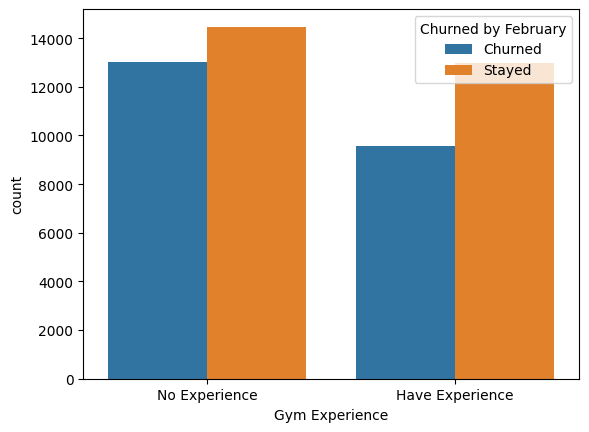

In [ ]:
# buat bar chart menggunakan seaborn
sns.barplot(
    data = data_one,
    x = "Gym Experience",
    y = "count",
    orient = "v",
    hue = "Churned by February"
)

**Insight:** Bagi member yang punya pengalaman gym sebelumnya, jumlah yang stay lebih banyak daripada yang churn. Namun untuk member yang belum pernah gym sama sekali, jumlah yang churn hampir sama mendekati jumlah yang stay. Dilihat secara sekilas, terdapat indikasi kalau member yang belum punya pengalaman gym sebelumnya lebih rentan untuk meng-cancel membershipnya. 

### 2. Bagaimana aktivitas join class antara member stay dan churn?

In [ ]:
# slicing data yang dibutuhkan
data_two = (df_visual.groupby(["Churned by February"])["Average Weekly Classes"].mean().reset_index())
data_two

,Churned by February,Average Weekly Classes
0,Churned,0.991977
1,Stayed,2.060787


<Axes: xlabel='Churned by February', ylabel='Average Weekly Classes'>

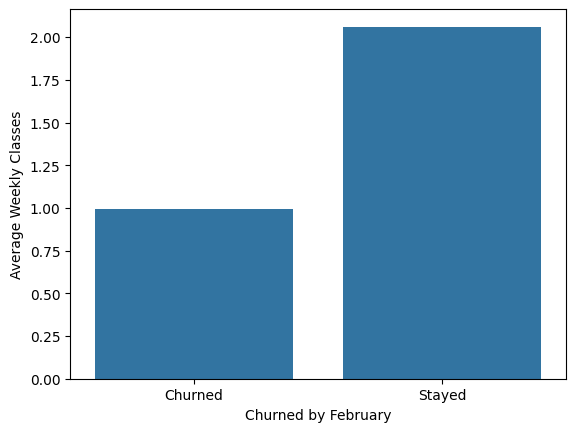

In [ ]:
# buat bar chart menggunakan seaborn
sns.barplot(
    data = data_two,
    x = "Churned by February",
    y = "Average Weekly Classes",
    orient = 'v'
)

**Insight:** Jika dilihat dari bar di atas, kita bisa melihat perbedaan behaviour member yang churned serta yang tidak berdasarkan rata-rata berapa kali dia mengikuti kelas dalam seminggu. 

Member yang churned hanya mengikuti rata-rata 1 kelas saja per minggu. Sedangkan member yang stayed bisa mengikuti rata-rata 2 kelas per minggu.

### 3. Berapa menit member menghabiskan rata-rata waktu di gym setiap kali datang? Bagaimana perbedaannya antara member yang stayed dan churned?

In [ ]:
# slicing data yang dibutuhkan
data_min = (df_visual.groupby(["Churned by February"])["Average Duration Minutes"].mean().reset_index())
data_min

,Churned by February,Average Duration Minutes
0,Churned,44.953856
1,Stayed,50.699417


In [ ]:
# slicing data yang dibutuhkan
data_visit = (df_visual.groupby(["Churned by February"])["Total Visit January"].mean().reset_index())
data_visit

,Churned by February,Total Visit January
0,Churned,5.820700
1,Stayed,11.233382


Text(0.5, 1.0, 'Average Total Visit')

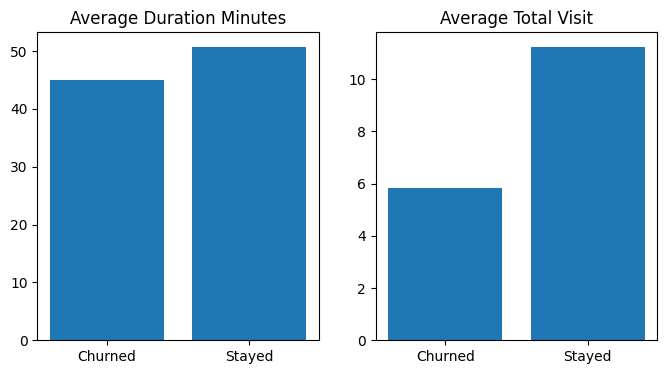

In [ ]:
# buat bar chart dengan matplotlib
fig, ax = plt.subplots(ncols=2, figsize=(8, 4))

ax[0].bar(
    data_min['Churned by February'],
    data_min['Average Duration Minutes']
)

ax[1].bar(
    data_visit['Churned by February'],
    data_visit['Total Visit January']
)

ax[0].set_title("Average Duration Minutes")
ax[1].set_title("Average Total Visit")

**Insight:** Berdasarkan bar chart di atas dapat dilihat bahwa member yang stayed menghabiskan durasi menit yang lebih lama di gym ketimbang member yang churned. Namun perbedaannya tidak begitu signifikan. Hal ini wajar karena metrik ini menghitung rata-rata durasi menit ketika member datang ke gym, bukan akumulasi dari total berapa menit dia stay di gym dalam kurun waktu tertentu.

Di sisi lain, jika dilihat berdasarkan total visit dalam Bulan Januari, baru terlihat perbedaan yang signifikan antara member yang churn dan member yang stay. Member yang stay memiliki total visit rata-rata hingga 11 kali sedangkan member yang churn memiliki total visit rata-rata 5-6 kali saja.

### 4. Apakah ada perbedaan goals dari member yang stay dan churn?

#### a. Primary Goals
Pertama kita bisa lihat berdasarkan persebaran goals utama pada member yang stay dan churn.

In [ ]:
# slicing data yang dibutuhkan
goals_churn = (df_visual[(df_visual['Churned by February'] == 'Churned')]["Primary Goal"].value_counts().reset_index())
goals_churn

,Primary Goal,count
0,weight_loss,10432
1,general_health,5343
2,muscle_gain,4930
3,event_prep,1855


In [ ]:
# slicing data yang dibutuhkan
goals_stay = (df_visual[(df_visual['Churned by February'] == 'Stayed')]["Primary Goal"].value_counts().reset_index())
goals_stay

,Primary Goal,count
0,weight_loss,12428
1,general_health,6683
2,muscle_gain,6070
3,event_prep,2259


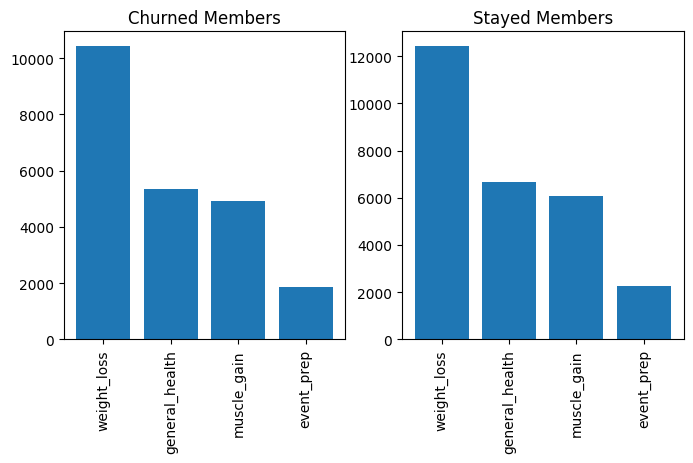

In [ ]:
# buat bar chart menggunakan matplotlib
fig, ax = plt.subplots(ncols=2, figsize=(8, 4))

ax[0].bar(
    goals_churn['Primary Goal'],
    goals_churn['count']
)

ax[1].bar(
    goals_stay['Primary Goal'],
    goals_stay['count']
)

ax[0].set_title("Churned Members")
ax[1].set_title("Stayed Members")

ax[0].tick_params(axis = 'x',labelrotation = 90)
ax[1].tick_params(axis = 'x',labelrotation = 90)

**Insight:** Secara visualisasi data, persebaran goal utama dari masing-masing member tidak beda jauh. Dengan goals paling banyak yaitu untuk menurunkan berat badan, kemudian diikuti oleh menjaga kesehatan, membangun otot, dan yang paling sedikit adalah persiapan untuk acara tertentu.

#### b. Goals agresiveness
Kedua kita bisa lihat berdasarkan goals agresiveness pada member yang stay dan churn. Goal agresiveness diukur berdasarkan tingkat realistis target pada member dengan 1 paling realistis dan 5 paling tidak realistis.

In [ ]:
# slicing data yang dibutuhkan
mtv_churn = (df_visual[(df_visual['Churned by February'] == 'Churned')]["Goal Agresiveness"].value_counts().reset_index())
mtv_churn

,Goal Agresiveness,count
0,5,5199
1,4,4865
2,3,4363
3,2,4227
4,1,3906


In [ ]:
# slicing data yang dibutuhkan
mtv_stay = (df_visual[(df_visual['Churned by February'] == 'Stayed')]["Goal Agresiveness"].value_counts().reset_index())
mtv_stay

,Goal Agresiveness,count
0,1,6110
1,2,5838
2,3,5504
3,4,5176
4,5,4812


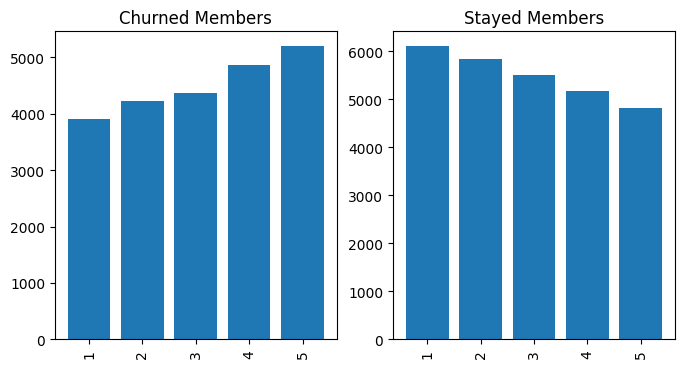

In [ ]:
# membuat bar chart dengan matplotlib
fig, ax = plt.subplots(ncols=2, figsize=(8, 4))

ax[0].bar(
    mtv_churn['Goal Agresiveness'],
    mtv_churn['count']
)

ax[1].bar(
    mtv_stay['Goal Agresiveness'],
    mtv_stay['count']
)

ax[0].set_title("Churned Members")
ax[1].set_title("Stayed Members")

ax[0].tick_params(axis = 'x',labelrotation = 90)
ax[1].tick_params(axis = 'x',labelrotation = 90)

**Insight:** Dari visualisasi data ini, kita baru melihat perbedaan yang signifikan dari tingkat realistis target para member. 

Member yang churn cenderung memiliki target yang kurang realistis, sehingga motivasinya sering kali terpengaruh karena targetnya sulit dicapai dan tidak sesuai dengan kemampuan diri.

Sedangkan, member yang stay cenderung memiliki target yang realistis. Sehingga motivasi mereka sedikit demi sedikit terbangun dengan target yang mudah dicapai dan kemudian bisa membangun target yang lebih tinggi lagi.

### 5. Apakah terdapat perbedaan usia antara member yang churn dan yang stay?

Untuk menjawab pertanyaan ini, kita perlu mengetahui persebaran data dari usia member dengan melakukan perhitungan statistika deskriptif berikut:

In [ ]:
# uji tendensi central
print(df["Age"].mean())
print(df["Age"].median())
print(df["Age"].mode().values[0])
print(df["Age"].std())

32.23222
32.0
16
9.494369738573207
16
71


1. Jika dilihat dari posisi mean dan median yang hampir sama, persebaran data terlihat normal. 
2. Kemudian dilihat dari standar deviasi, angkanya tergolong kecil sehingga persebaran data cenderung berkumpul di sekitar median. 
3. Namun dilihat dari modusnya yang 16 terdapat indikasi kalau bentuk kurva persebarannya sedikit miring ke kiri.

Maka dari itu kita akan melakukan beberapa uji normalitas lagi untuk mengetahui apakah data ini memiliki persebaran yang normal atau tidak.

**Uji K^2 D’Agostino**

In [ ]:
# uji K^2 D’Agostino
res = stats.normaltest(df["Age"])
print(res.pvalue)

2.2709897290135185e-191


Dari uji di atas, nilai p-value berada jauh di bawah nilai 0.05, artinya data tidak normal. Maka kita bisa lakukan tes selanjutnya.

**Uji Saphiro-Wilk**

In [ ]:
# uji saphiro-wilk
res = stats.shapiro(df["Age"])
print(res.pvalue)

1.6881222684281607e-56


c:\Users\DELL\miniconda3\envs\h8_env\lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 50000.
  res = hypotest_fun_out(*samples, **kwds)


Dari hasil p-value di bawah 0.05, maka data juga dinyatakan tidak normal. Maka kita bisa cek skewness dan kurtosis.

In [307]:
print(df["Age"].skew())
print(df["Age"].kurtosis())

0.24529770063999223
-0.3539846412877541


Dari hasil skewness yang masih di antara 0.5 dan 1 maka data ini masih tergolong normal dengan tingkat kemiringan yang moderate ke kiri. 

Sedangkan dari hasil kurtosis yang juga masih mendekati nilai 0, dan sedikit mengarah ke bentuk Platykurtic, maka data ini masih bisa disebut tergolong normal.

Dilihat dari tes uji tendensi sentral, skewness, dan kurtosis menyatakan data ini masih bisa tergolong persebaran data yang normal. Maka kita bisa lanjut menguji apakah terdapat perbedaan usia yang signifikan menggunakan Uji Two-Sample Independent Test.

**Uji Two-Sample Independent Test**

In [ ]:
# slicing data yang dibutuhkan
age_churn = df[df["Churned by February"] == 1][["Churned by February","Age"]]
age_stay = df[df["Churned by February"] == 0][["Churned by February","Age"]]

#tampilkan perbandingan mean usia per kategori member
age_table = df[["Churned by February","Age"]].groupby("Churned by February").mean()
age_table

,Age
Churned by February,
0,32.476749
1,31.934796


Terdapat perbedaan yaitu usia member yang churn lebih muda dari usia member yang stay. Namun perbedaan ini tidak signifikan secara kasat mata, maka kita perlu buktikan secara statistik apakah perbedaannya signifikan atau tidak.

Maka dari itu, kita simpulkan Hipotesis sebagai berikut:

***H0* : Usia member yang churn == Usia member yang stay**

***H1* : Usia member yang churn != Usia member yang stay**

In [ ]:
# uji tes 2 sample independen
t_stat, p_val = stats.ttest_ind(
    age_churn["Age"],
    age_stay["Age"],
    alternative = "two-sided"
)

print(t_stat)
print(p_val)

-6.353940592373149
2.1166893311986527e-10


Hasil p-value lebih kecil dari 0.05, maka tolak H0. 
Artinya terdapat perbedaan signifikan antara usia memebr yang churn dengan yang stay. Jika dilihat dari nilai t-stat yang negatif, maka rata-rata usia member yang churn secara signifikan lebih muda daripada rata-rata usia member yang stay. 

Implikasi bisnis: 
1. Member yang lebih muda atau di bawah usia 31 lebih cenderung untuk cancel membership
2. Terdapat dua dugaan, apakah hal ini dipengaruhi oleh faktor external (buying power member) atau internal (fasilitas atau layanan ketinggalan zaman dan kurang sesuai dengan anak muda)
3. Kita bisa membuat improvement pada faktor yang bisa kita kontrol, yaitu: 
    
    a. Melakukan retargeting ke target audience yang lebih mapan dengan buying power tinggi
    
    b. Melakukan peremajaan fasilitas dan layanan agar lebih modern sehingga audience yang lebih muda bisa nyaman

### 6. Antara booking personal trainer dan booking induction, manakah yang lebih mempengaruhi member untuk stay? 

Untuk menjawab pertanyaan ini kita perlu melakukan uji korelasi dari personal trainer dan induction terhadap churn. Maka dari itu kita perlu melakukan uji statistika inferensial dengan metode chi squared test karena semua data yang akan kita uji merupakan data categorical.

**a. Uji korelasi antara Personal Trainer dan Membership Churn**

In [ ]:
# buat table contingency
contingency_pt = pd.crosstab(df_visual["Personal Trainer"], df_visual["Churned by February"])
contingency_pt

Churned by February,Churned,Stayed
Personal Trainer,,
No,19967,22564
Yes,2593,4876


Berdasarkan tabel di atas, kita bisa lihat bahwa member yang tidak booking personal trainer lebih cenderung cancel membership daripada member yang booking personal trainer.

Maka kita bisa buat hipotesis sebagai berikut:

***H0* = Tidak terdapat hubungan antara Personal Trainer dan Membership Churn**

***H1* = Terdapat hubungan antara Personal Trainer dan Membership Churn**

In [ ]:
#uji chi squared test
res = stats.chi2_contingency(contingency_pt)

print(res.pvalue)

2.403770080135804e-85


Hasil p-value lebih kecil dari critical value 0.05, maka H0 ditolak.

Artinya, terdapat hubungan antara booking personal trainer dan membership churn.

Implikasi bisnis: 
1. Members yang menyewa personal trainer cenderung lebih banyak yang stay daripada cancel membership. 
2. Sedangkan untuk members yang tidak menyewa personal trainer, jumlah yang cancel membershipnya hampir sama dengan jumlah yang stay.
3. Hasil ini menunjukkan bahwa dari total member yang menyewa personal trainer persentasi yang stay jauh lebih banyak 

Saran:
1. Mendorong member baru untuk menyewa jasa personal trainer dengan diskon package
2. Melakukan promo bundling membership dan personal trainer, misal: gratis 3 sesi PT untuk member baru
3. Melakukan improvement kualitas PT dengan cara memberikan pelatihan tambahan mengenai body building serta pengetahuan tentang customers' satisfaction agar member puas dengan latihan yang diberikan oleh trainer.

**b. Uji korelasi antara Booking Induction dan Membership Churn**

In [298]:
contingency_ind = pd.crosstab(df_visual["Booked Induction"], df_visual["Churned by February"])
contingency_ind

Churned by February,Churned,Stayed
Booked Induction,,
No,13934,13495
Yes,8626,13945


Berdasarkan tabel di atas, kita bisa lihat bahwa member yang tidak booking induction lebih cenderung cancel membership daripada member yang booking induction.

Maka kita bisa buat hipotesis sebagai berikut:

***H0* = Tidak terdapat hubungan antara Booked Induction dan Membership Churn**

***H1* = Terdapat hubungan antara Booked Induction dan Membership Churn**

In [ ]:
# uji chi squared test
res2 = stats.chi2_contingency(contingency_ind)

print(res2.pvalue)

4.35726515706573e-174


Hasil p-value lebih kecil dari critical value 0.05, maka H0 ditolak.

Artinya, terdapat hubungan antara booking induction dan membership churn.

Implikasi bisnis: 
1. Members yang booking sesi induction cenderung lebih banyak yang stay daripada cancel membership. 
2. Sedangkan untuk members yang tidak booking induction, jumlah yang cancel membershipnya hampir sama dengan jumlah yang stay.
3. Hasil ini menunjukkan bahwa dari total member yang booking sesi induction, persentasi yang stay jauh lebih banyak 
4. Members yang tidak mengikuti sesi induction, terlebih jika dia tidak pernah ke gym sama sekali, akan merasa clueless ketika datang ke gym sehingga lama kelamaan mereka akan makin jarang datang dan berakhir dengan membership cancellation

Saran:
1. Menjadikan sesi induction sudah included dalam paket membership sehingga semua member baru bisa dipastikan mengikuti induction
2. Melakukan improvement dalam sesi induction, misal dibuat menjadi 2 sesi, sesi 1 induction dan sesi 2 PT consultation. Diharapkan member baru jadi tahu mereka harus melakukan latihan apa saja dan menjadi termotivasi untuk datang ke gym

## Conclusion

1. Member yang tidak memiliki pengalaman gym sebelumnya, atau bisa disebut first-timer, lebih rentan meng-cancel membershipnya. 
2. Berdasarkan behaviour members, yang cancel membership rata-rata hanya mengikuti 1 kelas per minggu saja. Berbeda dengan member yang stay, yang bsia mengikuti rata-rata 2 kelas per minggu. Ini belum termasuk dengan jumlah total visit mereka.
3. Sekarang, jika membahas tentang jumlah visit dan durasi menit per visit kita bisa melihat perbedaannya. Memang tidak ada perbedaan kasat mata antara rata-rata durasi menit member yang stay dan churn. Namun jika dilihat dari total visit dalam bulan januari, member yang stay bisa visit hingga rata-rata 11 kali sedangkan member yang churn hanya visit rata-rata 5-6 kali saja. 
4. Data di atas mengimplikasikan perbedaan motivasi antara kedua kelompok member. Jika dilihat dari persebaran goal utama, keduanya memiliki kemiripan. Namun jika dilihat dari tingkat realistis target, member yang churn cenderung memiliki target yang kurang realistis, sedangkan member yang stay cenderung memiliki target yang realistis.
5. Member yang lebih muda atau di bawah usia 31 lebih cenderung untuk cancel membership. Maka kita bisa melakukan re-targeting audience yang lebih mapan atau melakukan peremajaan fasilitas sehingga lebih modern.
6. Member yang bookign personal trainer atau booking induction keduanya lebih banyak yang stay daripada yang cancel. 

Maka solusi rekomendasi yang bisa diadopsi adalah sebagai berikut:
1. Mendorong member baru untuk menyewa jasa personal trainer dengan diskon package.
2. Melakukan promo bundling membership dan personal trainer, misal: gratis 3 sesi PT untuk member baru
3. Melakukan improvement kualitas PT dengan cara memberikan pelatihan tambahan mengenai body building serta pengetahuan tentang customers' satisfaction agar member puas dengan latihan yang diberikan oleh trainer.
4. Menjadikan sesi induction sudah included dalam paket membership sehingga semua member baru bisa dipastikan mengikuti induction
5. Melakukan improvement dalam sesi induction, misal dibuat menjadi 2 sesi, sesi 1 induction dan sesi 2 PT consultation. Diharapkan member baru jadi tahu mereka harus melakukan latihan apa saja dan menjadi termotivasi untuk datang ke gym
6. Sesi induction dan personal training penting untuk menyelaraskan target yang realistis bagi para member agar motivasinya terjaga.
7. Melakukan review jadwal kelas agar lebih sesuai dengan jadwal member. Memperbanyak kelas di jam after office hour.
